# A robot in a robosuite scene with `robotdesigner` (CPU MuJoCo simulator)

A robot arm is *data*; the environment is a TorchRL `EnvBase` built from one declarative `EnvConfig`.
This notebook builds a three-link arm, puts it in robosuite's `Lift` scene (a table and a cube), runs it, and then
runs the **same task** on other embodiments.

robosuite only supplies the assets here: the table, the cube and the rule that places the cube at every reset. The
simulation that steps everything is MuJoCo (named in `SimConfig`), the robot and its control law are ours, and success and
reward are defined in the config.

Install first: `pip install -e ".[env,robosuite]"` (add `ipykernel` or `jupyter` to run it).

## 1. Describe the robot

`chain()` generates a `ParametricArm`. Every dynamic parameter is explicit; `n` is a generator argument, not a config
field, and the arm has no pose: where it stands is a property of the scene, `TaskConfig.mount`. `default_mount("Lift")`
is the world pose where robosuite mounts a stock arm in this scene; it is just a `Pose` (the table top is at z = 0.8 m),
so any other pose works as well.

In [ ]:
import logging

import numpy as np
import torch

from robotdesigner import make_env
from robotdesigner.config import (
    ControlConfig, EnvConfig, FixedGains, InertiaScaledGains, MujocoOptions, SimConfig, TaskConfig, chain,
)
from robotdesigner.config import kinematics as kin
from robotdesigner.tasks.robosuite import LiftObject, ReachObject, RobosuiteParams, default_mount

mount = default_mount("Lift")                  # imports robosuite; its warnings about optional extras are harmless
logging.getLogger("robosuite_logs").setLevel(logging.WARNING)       # it logs an INFO line for every scene it loads
print("mount:", mount.pos)

arm = chain(
    n=3, axes="zyy", total_length=0.9, total_mass=3.0, radius=0.03,      # a yaw joint, then two pitch joints
    damping=0.5, armature=0.01, frictionloss=0.0, effort_limit=50.0, range=(-2.5, 2.5),
)
print("n =", arm.n, "| config_hash =", arm.config_hash)

[robosuite WARNING] No private macro file found! (macros.py:53)
[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)
[robosuite WARNING] To setup, run: python <site-packages>/robosuite/scripts/setup_macros.py (macros.py:55)
[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)
[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)
[robosuite INFO] Loading controller configuration from: <site-packages>/robosuite/controllers/config/robots/default_panda.json (composite_controller_factory.py:121)


mount: (-0.56, 0.0, 0.912)
n = 3 | config_hash = 287b31f43ec4


The numpy-only kinematics oracle gives the end-effector position without any simulator. At `q = 0` the arm is straight
along +x from the mount, which is the base pose the kinematics are given.

In [1]:
print(kin.forward(arm, np.zeros(3), mount).ee[:3, 3])               # the mount + (0.9, 0, 0)
print(kin.forward(arm, [0.0, 0.5, 0.5], mount).ee[:3, 3])

[0.34  0.    0.912]
[0.16536546 0.         0.51573104]


## 2. Describe the environment

Control, task and the simulation (the simulator and its options) all live in `EnvConfig`, and it has one hash. There are no hidden defaults.

The task is `robosuite/Lift`: the params object names the provider (its class) and the environment (`name="Lift"`). Its success is an *objective* on a scene object: `LiftObject("cube", height=0.84)` holds
when the cube's centre is at least 0.84 m above the floor (the table top is at 0.8 m). Because the objective defines
success, `success_tolerance` and `target_region` are `None`. `sim.scene` is `"empty"`: the arena brings its own floor.

In [2]:
def make_config(arm, num_envs=4, mode="joint_pos_abs", gains=None, action_scale=None,
                objective=None, max_episode_steps=100):
    return EnvConfig(
        robot=arm,
        control=ControlConfig(mode, gains or FixedGains(kp=60.0, kd=6.0), action_scale),
        task=TaskConfig(
            params=RobosuiteParams("Lift", {}, objective or LiftObject("cube", height=0.84),
                                   reset_noise=0.0, terminate_on_success=False),
            max_episode_steps=max_episode_steps, success_tolerance=None, target_region=None, mount=mount,
        ),
        sim=SimConfig(simulator="mujoco", num_envs=num_envs, device="cpu", dt=0.002,
                      integrator="euler", control_freq=50, seed=0, scene="empty",
                      options=MujocoOptions(self_collision=False)),
    )

cfg = make_config(arm)
print("env_hash =", cfg.env_hash)
assert EnvConfig.from_dict(cfg.to_dict()) == cfg      # configs round-trip through plain dicts

env_hash = 8bb4582d19c9


In [3]:
cfg.task

TaskConfig(params=RobosuiteParams(name='Lift', env_kwargs=('__map__',), objective=LiftObject(object='cube', height=0.84), reset_noise=0.0, terminate_on_success=False), max_episode_steps=100, success_tolerance=None, target_region=None)

## 3. Make the environment

`env = make_env(cfg)` is the one step from config to environment. It checks the config against the simulator's
capabilities and the task's provider first, and reports **every** problem at once.

In [4]:
env = make_env(cfg)
print(env.batch_size, env.device, env.robot_hash, env.env_hash)
print("action:", env.action_spec.shape, "| qpos:", env.observation_spec["proprio", "qpos"].shape)
print("task observations:", sorted(env.observation_spec["task"].keys()))

torch.Size([4]) cpu 287b31f43ec4 8bb4582d19c9
action: torch.Size([4, 3]) | qpos: torch.Size([4, 3])
task observations: ['cube_pos', 'cube_quat', 'ee_pos']


In [5]:
env

MujocoEnv()

In [6]:
from dataclasses import replace

try:      # three things wrong at once: the scene (the arena has its own floor), the device, the control mode
    make_env(replace(cfg, sim=replace(cfg.sim, device="cuda:0", scene="plain_floor"),
                     control=ControlConfig("ee_pos_delta", FixedGains(60.0, 6.0), None)))
except Exception as e:
    print(e)

simulator 'mujoco' cannot run this config (3 problems):
  - control.mode: simulator 'mujoco' does not support control mode 'ee_pos_delta'; supported: ['joint_pos_abs', 'joint_pos_delta', 'joint_torque', 'joint_vel']
  - sim.device: simulator 'mujoco' does not support device 'cuda:0'; supported: ['cpu']
  - sim.scene: must be 'empty' for robosuite tasks: the arena brings its own floor


## 4. Step by hand

The env never autoresets. `step_and_maybe_reset` is the driver-side autoreset; `_reset` masks select which rows to
reset. robosuite's sampler places the cube at every reset, each env with its own placement. Positions in the
observation are in the robot's base frame.

In [7]:
td = env.reset()
print("cube (base frame), per env:\n", td["task", "cube_pos"])
print("end effector (base frame):\n", td["task", "ee_pos"])

td["action"] = env.action_spec.rand()          # [num_envs, n] in [-1, 1]
td = env.step(td)
print("reward (minus the distance from the end effector to the cube):", td["next", "reward"].flatten())
print("episode_step:", td["next", "episode_step"].flatten())

cube (base frame), per env:
 tensor([[ 0.5388,  0.0290, -0.0808],
        [ 0.5547, -0.0069, -0.0808],
        [ 0.5585,  0.0030, -0.0808],
        [ 0.5896, -0.0266, -0.0808]])
end effector (base frame):
 tensor([[0.9000, 0.0000, 0.0000],
        [0.9000, 0.0000, 0.0000],
        [0.9000, 0.0000, 0.0000],
        [0.9000, 0.0000, 0.0000]])
reward (minus the distance from the end effector to the cube): tensor([-0.3675, -0.3448, -0.3395, -0.3131])
episode_step: tensor([1, 1, 1, 1])


In [8]:
# Partial reset: only env 0 returns to the home pose, and only its cube is placed again.
td = td["next"].clone()
cube_before = td["task", "cube_pos"].clone()
td["_reset"] = torch.tensor([[True], [False], [False], [False]])
td = env.reset(td)
print("episode_step:", td["episode_step"].flatten())                                  # env 0 -> 0, others unchanged
print("cube moved:", (td["task", "cube_pos"] != cube_before).any(dim=-1).tolist())    # only env 0

episode_step: tensor([0, 1, 1, 1])
cube moved: [True, False, False, False]


## 5. Roll out a random policy

In [9]:
traj = env.rollout(50)
print(traj.shape)
print("distance from the end effector to the cube at the end:", -traj["next", "reward"][:, -1].flatten())
print("cube lifted (success):", traj["next", "success"][:, -1].flatten().tolist())

torch.Size([4, 50])
distance from the end effector to the cube at the end: tensor([0.4717, 1.2789, 0.4645, 0.3889])
cube lifted (success): [False, False, False, False]


## 6. One task, several embodiments

The task never mentions `n` or link lengths. Here the same `TaskConfig` runs on arms with 2, 3 and 4 joints and the same
total length and mass. The cube is placed from the task's own random stream, which does not depend on the robot, so with
the same seed every arm gets **the same cube** at its first reset (the printed positions are identical) although the arms
have different numbers of joints.

In [10]:
def lift_arm(n, length=0.9):
    return chain(n=n, axes="z" + "y" * (n - 1), total_length=length, total_mass=3.0, radius=0.03,
                 damping=0.5, armature=0.01, frictionloss=0.0, effort_limit=50.0, range=(-2.5, 2.5))

for n in (2, 3, 4):
    e = make_env(make_config(lift_arm(n)))
    cube = e.reset()["task", "cube_pos"][0]
    t = e.rollout(30)
    print(f"n={n}  robot_hash={e.robot_hash}  env_hash={e.env_hash}  action dim={e.action_spec.shape[-1]}  "
          f"cube of env 0={cube.numpy().round(4)}  mean final dist={-t['next', 'reward'][:, -1].mean():.3f}")
    e.close()

n=2  robot_hash=0fbaa4867266  env_hash=27292c3d21be  action dim=2  cube of env 0=[ 0.5388  0.029  -0.0808]  mean final dist=0.495
n=3  robot_hash=287b31f43ec4  env_hash=8bb4582d19c9  action dim=3  cube of env 0=[ 0.5388  0.029  -0.0808]  mean final dist=0.570
n=4  robot_hash=723e793ab2fd  env_hash=8339acb08e60  action dim=4  cube of env 0=[ 0.5388  0.029  -0.0808]  mean final dist=0.438


## 7. The same scene, another objective

robosuite does not decide success or reward; the `objective` in the task's params does. `ReachObject` asks the end
effector to come within a tolerance of an object's centre. Only the objective changes, so the hash changes and the scene
and the robot stay as they are.

In [11]:
reach_cfg = make_config(arm, objective=ReachObject("cube", tolerance=0.08))
print(cfg.env_hash, "->", reach_cfg.env_hash, "| same robot:", reach_cfg.robot == cfg.robot)
print(reach_cfg.task.params.objective)

8bb4582d19c9 -> f044d84638ee | same robot: True
ReachObject(object='cube', tolerance=0.08)


## 8. Other control modes and inertia-scaled gains

`joint_pos_delta` integrates the action into a clipped position target; `joint_vel` tracks a velocity. With
`InertiaScaledGains` the gains follow the inertia each joint sees (evaluated at `home_qpos`), so differences between
embodiments are not just mismatched gains. The effective gains are recorded on the interface.

In [12]:
cfg_delta = make_config(arm, mode="joint_pos_delta", action_scale=0.05,
                        gains=InertiaScaledGains(bandwidth=20.0, damping_ratio=1.0))
env_delta = make_env(cfg_delta)
print("kp =", env_delta.interface.kp.round(2))
print("kd =", env_delta.interface.kd.round(2))

td = env_delta.reset()
for _ in range(3):
    td["action"] = torch.ones(4, 3)
    td = env_delta.step(td)["next"]
print("q_target after 3 steps:", env_delta.q_target[0])        # 3 * 0.05 per joint

kp = [330.88 101.92  16.96]
kd = [32.59  9.69  1.2 ]
q_target after 3 steps: [0.15 0.15 0.15]


## 9. Rendering (optional)

Needs an OpenGL context. On a headless machine, set `MUJOCO_GL=egl` before importing mujoco (restart the kernel).
Nothing else in the package needs rendering. The scene is the robosuite arena plus your robot; the arena's own cameras
are in the model, with the prefix `rs_`.

For MP4 / GIF videos, recording rollouts and comparing embodiments, see `scene_viz.ipynb`.

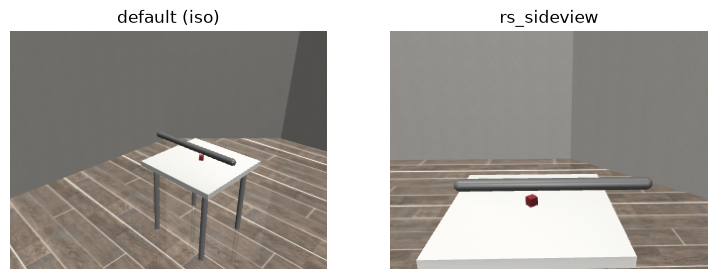

In [13]:
try:
    from robotdesigner.simulators.mujoco.render import render_rgb
    import matplotlib.pyplot as plt

    env.reset()
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    for ax, camera in zip(axes, [None, "rs_sideview"]):        # the default view, and a camera of the arena
        ax.imshow(render_rgb(env, env_index=0, camera=camera, size=(240, 320)))
        ax.set_title(camera or "default (iso)")
        ax.axis("off")
except Exception as e:                  # no GL context, or matplotlib missing
    print("rendering unavailable:", type(e).__name__, e)

In [14]:
env.close()
env_delta.close()